# TP2 · Clasificación supervisada — Bank Marketing
## Paso 2 · Clasificadores y validación cruzada

En este notebook:
1. Se eligen y justifican **dos métricas**.
2. Se entrenan los 4 clasificadores pedidos — **Naive Bayes, SVM, KNN y Random Forest** — con sus **hiperparámetros por defecto** (todavía **no** se ajusta ninguno; eso es el Paso 3).
3. Se evalúan con **k-fold cross-validation estratificada usando solo el conjunto de entrenamiento**.
4. Se comparan los **sets de variables** definidos en el Paso 1 (A, B, B + edad, C) y se elige uno para continuar.

**Datos usados:** solo `data/train.csv` (80 %). El test no se toca en este notebook.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from joblib import Parallel, delayed

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (recall_score, roc_auc_score, precision_score, f1_score,
                             confusion_matrix, roc_curve)

from tp2_comun import (RANDOM_STATE, RESULTADOS, SETS, cargar_split, agregar_features,
                       crear_preprocesador, columnas, estilo_graficos, guardar,
                       COLORES_SET, COLORES_MODELO, C_GRIS)
estilo_graficos()
RESULTADOS.mkdir(exist_ok=True)

X_train, y_train = cargar_split("train")
Xtr = agregar_features(X_train)          # reglas fijas del Paso 1 (sin leakage)
print("Train:", Xtr.shape, f"| % yes = {y_train.mean():.2%}")

Train: (32940, 21) | % yes = 11.27%


### 2.1 Elección de métricas

El problema: el banco quiere **priorizar a quién llamar**. Las clases están desbalanceadas (11.3 % `yes`), por lo que **accuracy queda descartada**: decir siempre "no" da 88.7 % de accuracy sin encontrar a ningún cliente.

Definimos `yes` como **clase positiva**. Los dos errores posibles:
- **Falso negativo (FN):** el modelo dice "no llamar" a un cliente que **sí** habría contratado → se **pierde un cliente** (ingreso perdido).
- **Falso positivo (FP):** se llama a alguien que no contrata → se pierde el costo de una llamada.

Consideramos **más grave el FN**: una llamada de más es barata; un depósito perdido no.

**Métrica 1 · Recall (sensibilidad) de la clase `yes`** = TP / (TP + FN)
De todos los clientes que **sí** contratarían, ¿a qué proporción detecta el modelo? Es la métrica que penaliza directamente el error que más nos importa (igual que en el ejemplo de diagnóstico de cáncer de la clase 4: umbral bajo / recall alto).

**Métrica 2 · ROC-AUC**
El recall por sí solo se puede "hacer trampa": un modelo que llama a **todos** tiene recall = 1. Necesitamos una métrica que mida si el modelo realmente **separa** a los interesados de los no interesados. El AUC:
- **no depende del umbral**: evalúa el *ranking* de clientes por probabilidad/score (justo lo que necesita el banco para priorizar llamadas),
- es **insensible al desbalance** (TPR y FPR se calculan dentro de cada clase),
- 0.5 = azar, 1 = clasificador ideal.

Como complemento (no para decidir) se reporta también la **precisión**, para ver el costo en falsas alarmas del recall obtenido.

> **Nota sobre el umbral:** con el umbral por defecto (0.5) y clases tan desbalanceadas, el recall será bajo para todos los modelos. Eso **no** se corrige acá (sería ajustar el modelo): se elegirá el umbral en el modelo final con la curva ROC (criterio del punto más cercano a (0, 1), visto en la clase 4). El AUC indica qué modelo tiene más margen para mejorar con ese ajuste.

### 2.2 Modelos (hiperparámetros por defecto de scikit-learn)

| Modelo | Configuración por defecto | Cómo funciona / qué esperar |
|---|---|---|
| **Naive Bayes** | `GaussianNB()` | Generativo: asume variables **independientes** dada la clase y cada una **gaussiana**. Nuestros datos violan ambos supuestos (one-hot binarias, `campaign` muy asimétrica, `contactado_antes` ≈ `poutcome_success`). |
| **SVM** | `SVC()` → kernel RBF, `C = 1`, `gamma = 'scale'` | Busca el hiperplano de margen máximo en el espacio del kernel; necesita escalado (lo tiene). Score continuo = distancia al hiperplano (`decision_function`). |
| **KNN** | `KNeighborsClassifier()` → `k = 5`, pesos uniformes, distancia euclídea | Vota la clase de los 5 vecinos más cercanos; sensible a escalas y a dimensiones poco informativas. Con k chico → alta varianza. |
| **Random Forest** | `RandomForestClassifier()` → 100 árboles, sin límite de profundidad | Bagging + subconjunto aleatorio de variables por split. Árboles sin podar → probable **overfitting** en train. |

Cada modelo va dentro de un `Pipeline(preprocesador → modelo)`, así **el escalado y el One-Hot se ajustan solo con los folds de entrenamiento** de cada iteración.

In [2]:
MODELOS = {
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
}

def crear_pipeline(set_nombre, modelo_nombre):
    return Pipeline([("pre", crear_preprocesador(set_nombre)),
                     ("modelo", clone(MODELOS[modelo_nombre]))])

crear_pipeline("B · EDA", "SVM")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

### 2.3 Validación cruzada estratificada (k = 5)

- `StratifiedKFold(n_splits=5, shuffle=True)`: cada fold mantiene el 11.3 % de `yes`.
- **Los mismos 5 folds** para todos los modelos y sets → la comparación es justa (las diferencias no se deben a particiones distintas).
- En cada fold: se ajusta el pipeline con 4/5 de train y se evalúa en el 1/5 restante (**validación**). También se mide en los propios datos de entrenamiento del fold, para ver el *gap* train–validación (indicio de overfitting).
- Se guardan las **predicciones fuera de fold** (cada cliente de train es predicho por el modelo que no lo vio) para construir la curva ROC y la matriz de confusión.

**Costo computacional:** 4 sets × 4 modelos × 5 folds = 80 entrenamientos; SVM con kernel RBF tarda ~1.5 min por fold sobre ~26 000 filas. Se paralelizan los entrenamientos y los resultados se guardan en `resultados/paso2_cv.joblib` para no recalcular (poner `RECALCULAR = True` para rehacerlo).

In [3]:
K = 5
cv = StratifiedKFold(n_splits=K, shuffle=True, random_state=RANDOM_STATE)
FOLDS = list(cv.split(Xtr, y_train))

def score_continuo(pipe, X):
    # Probabilidad de 'yes' si el modelo la da; si no (SVC), la distancia al hiperplano
    if hasattr(pipe, "predict_proba"):
        return pipe.predict_proba(X)[:, 1]
    return pipe.decision_function(X)

def metricas(y, pred, score):
    return {"recall": recall_score(y, pred), "auc": roc_auc_score(y, score),
            "precision": precision_score(y, pred, zero_division=0), "f1": f1_score(y, pred)}

def evaluar_fold(set_nombre, modelo_nombre, k, idx_tr, idx_va):
    cols = columnas(set_nombre)
    X_a, y_a = Xtr.iloc[idx_tr][cols], y_train.iloc[idx_tr]
    X_v, y_v = Xtr.iloc[idx_va][cols], y_train.iloc[idx_va]
    t0 = time.time()
    pipe = crear_pipeline(set_nombre, modelo_nombre).fit(X_a, y_a)
    t_fit = time.time() - t0
    s_v, p_v = score_continuo(pipe, X_v), pipe.predict(X_v)
    s_a, p_a = score_continuo(pipe, X_a), pipe.predict(X_a)
    fila = {"set": set_nombre, "modelo": modelo_nombre, "fold": k, "t_fit_s": t_fit}
    fila.update({f"val_{m}": v for m, v in metricas(y_v, p_v, s_v).items()})
    fila.update({f"train_{m}": v for m, v in metricas(y_a, p_a, s_a).items()})
    return fila, (set_nombre, modelo_nombre, idx_va, s_v, p_v)

RECALCULAR = False
CACHE = RESULTADOS / "paso2_cv.joblib"

if CACHE.exists() and not RECALCULAR:
    res_folds, oof = joblib.load(CACHE)
    print("Resultados cargados de", CACHE)
else:
    # SVM primero: son las tareas más largas y conviene que arranquen antes
    orden = sorted(MODELOS, key=lambda m: m != "SVM")
    tareas = [(s, m, k, tr, va) for m in orden for s in SETS for k, (tr, va) in enumerate(FOLDS)]
    t0 = time.time()
    salida = Parallel(n_jobs=-1, verbose=0)(delayed(evaluar_fold)(*t) for t in tareas)
    print(f"{len(tareas)} entrenamientos en {(time.time() - t0)/60:.1f} min")
    res_folds = pd.DataFrame([f for f, _ in salida])
    # Predicciones fuera de fold (OOF): cada fila de train predicha por el modelo que no la vio
    oof = {}
    for s, m, idx, sc, pr in (o for _, o in salida):
        d = oof.setdefault((s, m), {"score": np.zeros(len(Xtr)), "pred": np.zeros(len(Xtr), int)})
        d["score"][idx], d["pred"][idx] = sc, pr
    joblib.dump((res_folds, oof), CACHE)

res_folds.round(3).head()

Resultados cargados de resultados\paso2_cv.joblib


,set,modelo,fold,t_fit_s,val_recall,val_auc,val_precision,val_f1,train_recall,train_auc,train_precision,train_f1
0,A · Completo,SVM,0,586.676,0.253,0.707,0.660,0.366,0.266,0.897,0.721,0.388
1,A · Completo,SVM,1,462.978,0.244,0.703,0.656,0.356,0.258,0.902,0.716,0.379
2,A · Completo,SVM,2,476.255,0.252,0.700,0.630,0.360,0.272,0.907,0.704,0.393
3,A · Completo,SVM,3,576.421,0.230,0.695,0.673,0.343,0.263,0.899,0.717,0.385
4,A · Completo,SVM,4,476.127,0.242,0.707,0.677,0.357,0.276,0.898,0.710,0.398


### 2.4 Resultados: modelos × sets de variables
Media ± desvío estándar sobre los 5 folds de **validación**.

In [4]:
ORDEN_MOD = list(MODELOS)
ORDEN_SET = list(SETS)
agg = (res_folds.groupby(["modelo", "set"])
       [["val_recall", "val_auc", "val_precision", "val_f1", "train_recall", "train_auc", "t_fit_s"]]
       .agg(["mean", "std"]))

tabla = pd.DataFrame({
    "Recall (val)":    agg[("val_recall", "mean")].map("{:.3f}".format) + " ± " + agg[("val_recall", "std")].map("{:.3f}".format),
    "ROC-AUC (val)":   agg[("val_auc", "mean")].map("{:.3f}".format) + " ± " + agg[("val_auc", "std")].map("{:.3f}".format),
    "Precisión (val)": agg[("val_precision", "mean")].map("{:.3f}".format),
    "Recall (train)":  agg[("train_recall", "mean")].map("{:.3f}".format),
    "AUC (train)":     agg[("train_auc", "mean")].map("{:.3f}".format),
    "t ajuste [s]":    agg[("t_fit_s", "mean")].map("{:.1f}".format),
}).reindex(pd.MultiIndex.from_product([ORDEN_MOD, ORDEN_SET]))
tabla

Recall (val)  ROC-AUC (val) Precisión (val)  \
Naive Bayes   A · Completo      0.601 ± 0.023  0.766 ± 0.012           0.309   
              B · EDA           0.539 ± 0.027  0.759 ± 0.013           0.315   
              B + edad          0.506 ± 0.021  0.758 ± 0.014           0.332   
              C · Sin contexto  0.626 ± 0.033  0.718 ± 0.016           0.202   
SVM           A · Completo      0.244 ± 0.009  0.702 ± 0.005           0.659   
              B · EDA           0.256 ± 0.011  0.699 ± 0.010           0.654   
              B + edad          0.255 ± 0.011  0.696 ± 0.012           0.655   
              C · Sin contexto  0.198 ± 0.005  0.645 ± 0.008           0.665   
KNN           A · Completo      0.295 ± 0.018  0.725 ± 0.010           0.535   
              B · EDA           0.286 ± 0.025  0.730 ± 0.006           0.522   
              B + edad          0.288 ± 0.025  0.731 ± 0.008           0.530   
              C · Sin contexto  0.202 ± 0.014  0.652 ± 0.005           0.522   
Random Forest A · Completo      0.288 ± 0.008  0.777 ± 0.007           0.545   
              B · EDA           0.296 ± 0.015  0.744 ± 0.008           0.456   
              B + edad          0.298 ± 0.011  0.744 ± 0.007           0.459   
              C · Sin contexto  0.217 ± 0.003  0.664 ± 0.008           0.404   

                               Recall (train) AUC (train) t ajuste [s]  
Naive Bayes   A · Completo              0.604       0.768          0.8  
              B · EDA                   0.543       0.761          0.6  
              B + edad                  0.508       0.760          0.7  
              C · Sin contexto          0.628       0.721          0.5  
SVM           A · Completo              0.267       0.901        515.7  
              B · EDA                   0.274       0.849        444.6  
              B + edad                  0.273       0.847        377.3  
              C · Sin contexto          0.204       0.766        251.0  
KNN           A · Completo              0.384       0.926          0.7  
              B · EDA                   0.390       0.924          0.5  
              B + edad                  0.389       0.924          0.6  
              C · Sin contexto          0.269       0.881          0.5  
Random Forest A · Completo              0.970       1.000         14.9  
              B · EDA                   0.830       0.996         12.1  
              B + edad                  0.831       0.996          9.8  
              C · Sin contexto          0.610       0.975          6.0

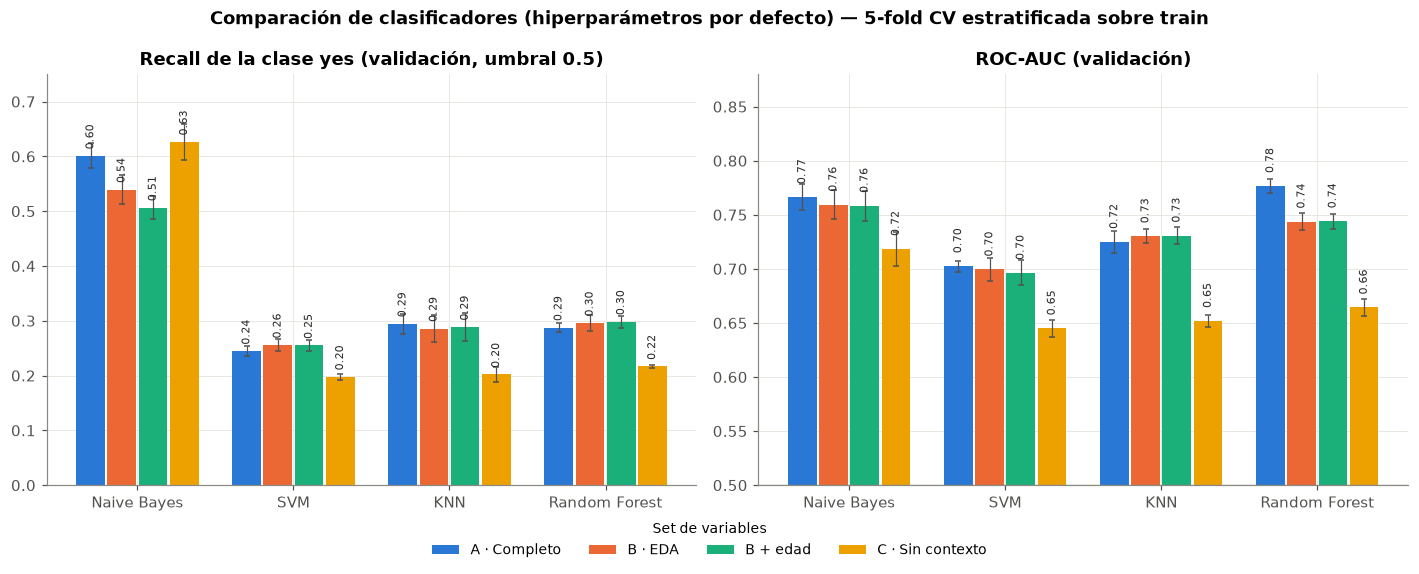

In [5]:
def barras_agrupadas(ax, metrica, titulo, ylim):
    m = res_folds.groupby(["modelo", "set"])[f"val_{metrica}"].agg(["mean", "std"])
    n = len(ORDEN_SET); ancho = 0.8 / n; x = np.arange(len(ORDEN_MOD))
    for i, s in enumerate(ORDEN_SET):
        medias = [m.loc[(mod, s), "mean"] for mod in ORDEN_MOD]
        desv = [m.loc[(mod, s), "std"] for mod in ORDEN_MOD]
        pos = x - 0.4 + ancho * (i + 0.5)
        ax.bar(pos, medias, width=ancho * 0.92, yerr=desv, capsize=2, color=COLORES_SET[s],
               label=s, error_kw={"elinewidth": 0.8, "ecolor": "#52514e"})
        for xp, v in zip(pos, medias):
            ax.text(xp, v + 0.012, f"{v:.2f}", ha="center", va="bottom", fontsize=7, rotation=90, color="#2b2b2a")
    ax.set_xticks(x, ORDEN_MOD)
    ax.set(title=titulo, ylim=ylim)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
barras_agrupadas(axes[0], "recall", "Recall de la clase yes (validación, umbral 0.5)", (0, 0.75))
barras_agrupadas(axes[1], "auc", "ROC-AUC (validación)", (0.5, 0.88))
axes[1].axhline(0.5, color=C_GRIS, lw=0.8)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, title="Set de variables", ncols=4, fontsize=9, title_fontsize=9,
           loc="lower center", bbox_to_anchor=(0.5, -0.08), frameon=False)
fig.suptitle("Comparación de clasificadores (hiperparámetros por defecto) — 5-fold CV estratificada sobre train",
             fontweight="bold")
guardar("08_cv_modelos_x_sets")

#### ¿Qué set de variables conviene? (efecto promedio sobre los 4 modelos)

In [6]:
por_set = (res_folds.groupby("set")[["val_recall", "val_auc"]].mean()
           .reindex(ORDEN_SET).rename(columns={"val_recall": "Recall medio", "val_auc": "AUC medio"}))
por_set["Δ AUC vs B"] = por_set["AUC medio"] - por_set.loc["B · EDA", "AUC medio"]
por_set["Δ Recall vs B"] = por_set["Recall medio"] - por_set.loc["B · EDA", "Recall medio"]
por_set["n° variables"] = [len(columnas(s)) for s in ORDEN_SET]
por_set.round(4)

,Recall medio,AUC medio,Δ AUC vs B,Δ Recall vs B,n° variables
set,,,,,
A · Completo,0.3568,0.7426,0.0094,0.0126,19
B · EDA,0.3442,0.7332,0.0000,0.0000,14
B + edad,0.3370,0.7323,-0.0008,-0.0073,15
C · Sin contexto,0.3106,0.6699,-0.0633,-0.0336,10


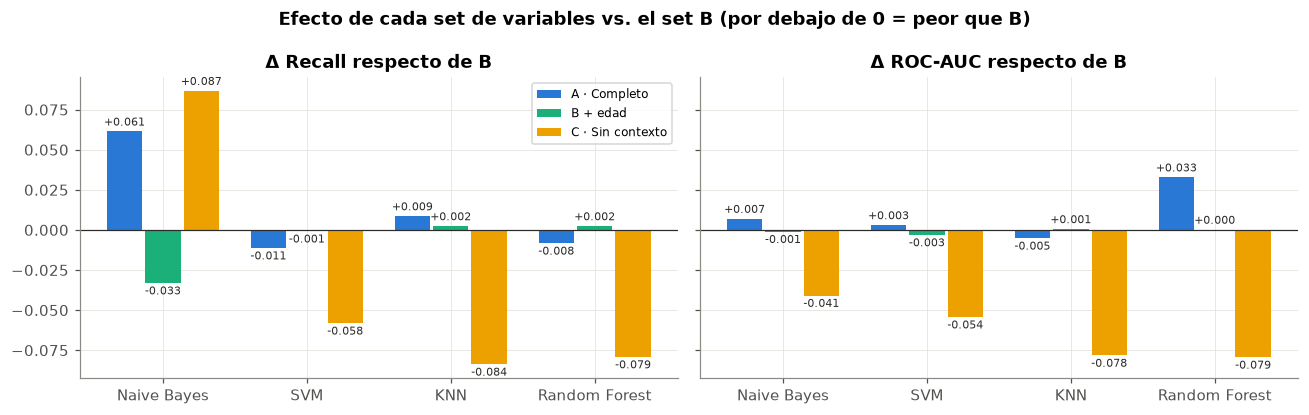

In [7]:
# Diferencia de cada set respecto de B, por modelo (validación)
base = res_folds[res_folds.set == "B · EDA"].set_index(["modelo", "fold"])[["val_recall", "val_auc"]]
dif = []
for s in [x for x in ORDEN_SET if x != "B · EDA"]:
    otro = res_folds[res_folds.set == s].set_index(["modelo", "fold"])[["val_recall", "val_auc"]]
    d = (otro - base).groupby("modelo").mean()
    d["set"] = s
    dif.append(d)
dif = pd.concat(dif).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
otros = [x for x in ORDEN_SET if x != "B · EDA"]
for ax, met, tit in zip(axes, ["val_recall", "val_auc"], ["Δ Recall respecto de B", "Δ ROC-AUC respecto de B"]):
    ancho = 0.8 / len(otros); x = np.arange(len(ORDEN_MOD))
    for i, s in enumerate(otros):
        v = dif[dif.set == s].set_index("modelo").reindex(ORDEN_MOD)[met].values
        pos = x - 0.4 + ancho * (i + 0.5)
        ax.bar(pos, v, width=ancho * 0.92, color=COLORES_SET[s], label=s)
        for xp, val in zip(pos, v):
            ax.text(xp, val + (0.002 if val >= 0 else -0.002), f"{val:+.3f}", ha="center",
                    va="bottom" if val >= 0 else "top", fontsize=7, color="#2b2b2a")
    ax.axhline(0, color="#2b2b2a", lw=0.8)
    ax.set_xticks(x, ORDEN_MOD); ax.set_title(tit)
axes[0].legend(fontsize=8)
fig.suptitle("Efecto de cada set de variables vs. el set B (por debajo de 0 = peor que B)", fontweight="bold")
guardar("09_delta_vs_setB")

#### ¿Por qué Random Forest mejora con el set A? (diagnóstico)
El set A le da a RF **+0.033 de AUC**, mientras que a los demás modelos casi no les cambia nada. Para entender qué variables lo explican, agregamos al set B **una por vez** las variables que el EDA había descartado (mismos 5 folds, solo RF porque es rápido):

In [8]:
from sklearn.model_selection import cross_validate
B = SETS["B · EDA"]
variantes = {
    "B · EDA": B,
    "B + euribor3m": {"num": B["num"] + ["euribor3m"], "cat": B["cat"]},
    "B + emp.var.rate": {"num": B["num"] + ["emp.var.rate"], "cat": B["cat"]},
    "B + pdays": {"num": B["num"] + ["pdays"], "cat": B["cat"]},
    "B + housing, loan, day_of_week": {"num": B["num"], "cat": B["cat"] + ["housing", "loan", "day_of_week"]},
}
filas = []
for nombre, s in variantes.items():
    SETS["_tmp"] = s
    pipe = Pipeline([("pre", crear_preprocesador("_tmp")),
                     ("modelo", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])
    r = cross_validate(pipe, Xtr[columnas("_tmp")], y_train, cv=FOLDS, scoring=["roc_auc", "recall"])
    filas.append({"variante": nombre, "AUC RF (val)": r["test_roc_auc"].mean(), "Recall RF (val)": r["test_recall"].mean()})
del SETS["_tmp"]
print("Valores distintos de cada variable macro en train:")
print(Xtr[["euribor3m", "nr.employed", "emp.var.rate", "cons.price.idx", "cons.conf.idx"]].nunique().to_string())
pd.DataFrame(filas).set_index("variante").round(3)

Valores distintos de cada variable macro en train:
euribor3m         312
nr.employed        11
emp.var.rate       10
cons.price.idx     26
cons.conf.idx      26


,AUC RF (val),Recall RF (val)
variante,,
B · EDA,0.744,0.296
B + euribor3m,0.766,0.297
B + emp.var.rate,0.745,0.297
B + pdays,0.746,0.305
"B + housing, loan, day_of_week",0.763,0.282


#### Interpretación: sets de variables

**A (completo) vs. B (EDA)** — en promedio A es apenas mejor (+0.009 AUC, +0.013 recall), pero el efecto depende del modelo:
- **KNN**: B es ligeramente mejor en AUC (−0.005 con A). ✔ Hipótesis confirmada: menos dimensiones poco informativas → distancias más útiles.
- **SVM**: prácticamente igual (+0.003). Las variables extra no le aportan ni le quitan.
- **Naive Bayes**: A algo mejor (+0.007 AUC, +0.061 recall). ✘ La hipótesis no se cumple del todo: las variables macro correlacionadas suman evidencia "repetida" y empujan más casos por encima del umbral (sube el recall), pero el ranking (AUC) casi no cambia.
- **Random Forest**: A claramente mejor (**+0.033 AUC**). ✘ Hipótesis refutada → se investigó en el diagnóstico.

**Diagnóstico de RF:** la mejora viene de `euribor3m` (+0.022 AUC) y de `housing`/`loan`/`day_of_week` (+0.019), mientras que `emp.var.rate` y `pdays` no aportan nada (redundantes, como predijo el EDA). Pero `housing`, `loan` y `day_of_week` **no discriminan por sí solas** (tasa ~11 % en todas sus categorías). La explicación: `euribor3m` tiene **312 valores distintos** (casi uno por día de campaña) y `day_of_week` combinado con `month` y los indicadores macro **identifica la semana/día exacto de la llamada**. Los árboles profundos de RF aprenden *"qué días la campaña funcionó bien"*. Como el split es aleatorio, train y validación comparten esos mismos días y eso mejora la CV, pero **no generalizaría a una campaña futura** (días que el modelo nunca vio). Es una forma de *leakage temporal*.

**B + edad** — no mejora a ningún modelo (Δ AUC ≈ 0) y a Naive Bayes le baja el recall (−0.033). ✘ Hipótesis refutada: la información de los extremos de edad ya está en `job` (`student`, `retired`), así que `edad_grupo` es redundante (y para NB es evidencia duplicada). **Se descarta.**

**C (sin contexto temporal)** — caída fuerte y consistente en los 4 modelos (**−0.04 a −0.08 de AUC**). Gran parte de lo que los modelos aprenden es *el momento* de la llamada (mes y situación económica), no el perfil del cliente. (El recall de NB sube a 0.63, pero su precisión cae a 0.20 y el AUC baja: predice "yes" más seguido, no mejor.) **Limitación importante**: en una campaña futura con otro contexto económico, el desempeño puede ser menor al estimado.

**Decisión → se continúa con el set B (14 variables):**
1. Para 3 de los 4 modelos la diferencia con A es mínima (≤ 0.007 AUC).
2. La ventaja de A en RF proviene de variables que funcionan como "huella de la fecha" y no generalizarían a campañas nuevas: preferimos una estimación algo menor pero más honesta.
3. Menos variables → modelo más simple y más rápido (relevante para SVM en el Paso 3).

### 2.5 Análisis con el set elegido

In [9]:
SET_ELEGIDO = 'B · EDA'
print("Set elegido para los pasos siguientes:", SET_ELEGIDO, "→", len(columnas(SET_ELEGIDO)), "variables")

Set elegido para los pasos siguientes: B · EDA → 14 variables


#### Train vs. validación (¿overfitting / underfitting?)

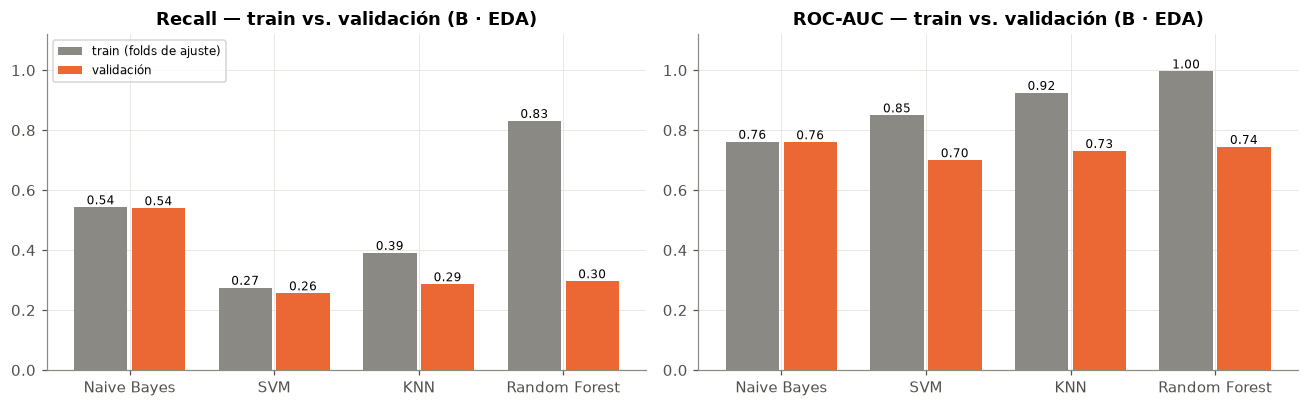

,train_recall,val_recall,train_auc,val_auc
modelo,,,,
Naive Bayes,0.543,0.539,0.761,0.759
SVM,0.274,0.256,0.849,0.699
KNN,0.390,0.286,0.924,0.730
Random Forest,0.830,0.296,0.996,0.744


In [10]:
sub = res_folds[res_folds.set == SET_ELEGIDO].groupby("modelo")[
    ["train_recall", "val_recall", "train_auc", "val_auc"]].mean().reindex(ORDEN_MOD)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, met, tit in zip(axes, ["recall", "auc"], ["Recall", "ROC-AUC"]):
    x = np.arange(len(ORDEN_MOD))
    for j, (parte, col, alfa) in enumerate([("train", "#8a8984", 1), ("val", "#eb6834", 1)]):
        v = sub[f"{parte}_{met}"].values
        ax.bar(x - 0.2 + 0.4 * j, v, width=0.37, color=col, label="train (folds de ajuste)" if parte == "train" else "validación")
        for xp, val in zip(x - 0.2 + 0.4 * j, v):
            ax.text(xp, val + 0.01, f"{val:.2f}", ha="center", fontsize=8)
    ax.set_xticks(x, ORDEN_MOD); ax.set(title=f"{tit} — train vs. validación ({SET_ELEGIDO})", ylim=(0, 1.12))
axes[0].legend(fontsize=8, loc="upper left")
guardar("10_train_vs_val")
sub.round(3)

**Lectura de overfitting / underfitting (set B, hiperparámetros por defecto):**
- **Random Forest — overfitting fuerte:** AUC 0.996 y recall 0.83 en train vs. 0.744 y 0.30 en validación. Árboles sin límite de profundidad memorizan el entrenamiento. → En el Paso 3: `max_depth`, `n_estimators`.
- **KNN — overfitting:** AUC 0.924 (train) vs. 0.730 (val). Con `k = 5` el modelo tiene bajo sesgo y alta varianza (clase 9). → Paso 3: `k` y ponderación por distancia.
- **SVM — overfitting moderado:** 0.849 vs. 0.699, y es el de menor AUC en validación. → Paso 3: `C` (y/o kernel).
- **Naive Bayes — sin gap** (0.761 vs. 0.759): no sobreajusta, pero es un modelo muy simple y con supuestos violados (alto sesgo). No tiene un hiperparámetro relevante que lo mejore mucho.

#### Curvas ROC (predicciones fuera de fold)
Cada punto de train fue predicho por el modelo del fold que **no** lo usó para entrenar, así que la curva refleja desempeño en datos no vistos.

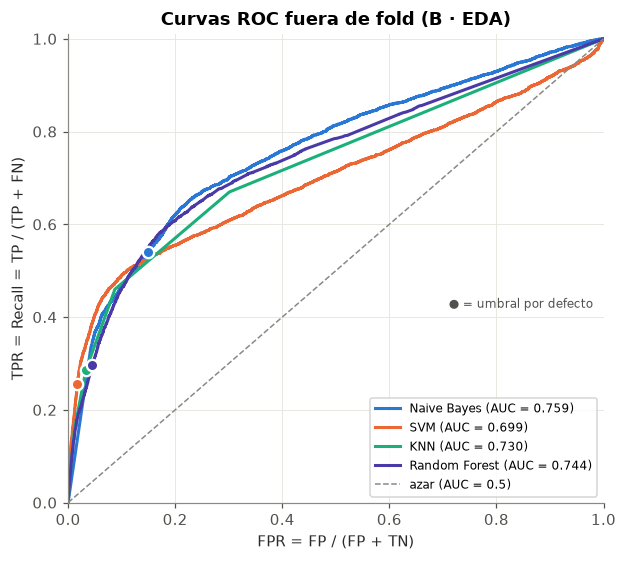

In [11]:
fig, ax = plt.subplots(figsize=(5.8, 5.2))
for m in ORDEN_MOD:
    sc = oof[(SET_ELEGIDO, m)]["score"]
    fpr, tpr, _ = roc_curve(y_train, sc)
    ax.plot(fpr, tpr, lw=2, color=COLORES_MODELO[m], label=f"{m} (AUC = {roc_auc_score(y_train, sc):.3f})")
    # punto del umbral por defecto (predicción con 0.5 / decision_function = 0)
    cm = confusion_matrix(y_train, oof[(SET_ELEGIDO, m)]["pred"])
    tn, fp, fn, tp = cm.ravel()
    ax.scatter(fp / (fp + tn), tp / (tp + fn), s=55, color=COLORES_MODELO[m], edgecolor="white", linewidth=1.5, zorder=3)
ax.plot([0, 1], [0, 1], ls="--", color=C_GRIS, lw=1, label="azar (AUC = 0.5)")
ax.set(xlabel="FPR = FP / (FP + TN)", ylabel="TPR = Recall = TP / (TP + FN)",
       title=f"Curvas ROC fuera de fold ({SET_ELEGIDO})", xlim=(0, 1), ylim=(0, 1.01))
ax.legend(fontsize=8, loc="lower right")
ax.text(0.98, 0.42, "● = umbral por defecto", ha="right", fontsize=8, color="#52514e")
guardar("11_roc_oof")

#### Matrices de confusión (predicciones fuera de fold, umbral por defecto)

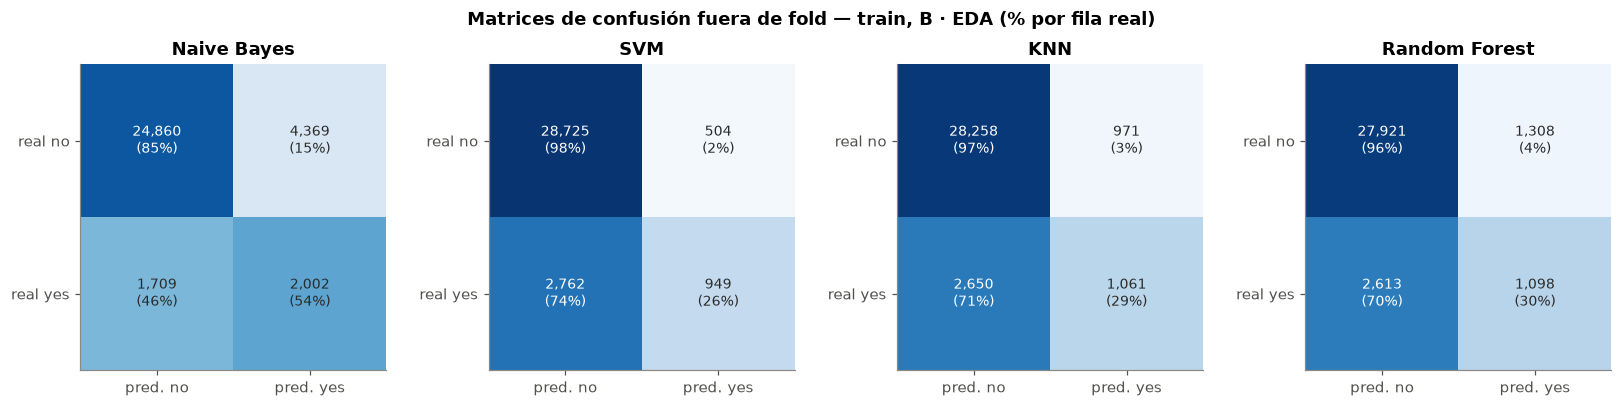

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, m in zip(axes, ORDEN_MOD):
    cm = confusion_matrix(y_train, oof[(SET_ELEGIDO, m)]["pred"])
    pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({pct[i, j]:.0%})", ha="center", va="center", fontsize=9,
                    color="white" if pct[i, j] > 0.6 else "#2b2b2a")
    ax.set_xticks([0, 1], ["pred. no", "pred. yes"]); ax.set_yticks([0, 1], ["real no", "real yes"])
    ax.grid(False); ax.set_title(m)
fig.suptitle(f"Matrices de confusión fuera de fold — train, {SET_ELEGIDO} (% por fila real)", fontweight="bold")
guardar("12_matrices_confusion")

**Lectura de la ROC y las matrices de confusión:**
- Con el umbral por defecto, **SVM, KNN y RF son muy conservadores**: detectan solo el 26–30 % de los clientes interesados (se pierden ~2 600 de 3 711) a cambio de pocas falsas alarmas (2–4 % de los `no`).
- **Naive Bayes** detecta el 54 % (2 002 clientes), a costa de 4 369 llamadas de más (precisión 0.32).
- Pero eso **no significa que NB sea mucho mejor**: en la curva ROC, NB y RF están muy cerca (AUC 0.759 vs. 0.744) y cada punto ● es solo *un* umbral distinto. El recall con umbral 0.5 depende de cómo cada modelo escala sus probabilidades; el AUC compara a todos en todos los umbrales. Bajando el umbral, RF también podría alcanzar recalls de ~0.6.
- En la zona de muy pocas falsas alarmas (FPR < 0.1), SVM es incluso competitivo, aunque luego se queda atrás.
- La curva de **KNN es "a tramos"**: con `k = 5` la probabilidad solo puede valer 0, 0.2, 0.4, … 1 → solo 6 umbrales posibles, ranking muy grueso. Un `k` mayor también mejoraría esto.

### 2.6 Conclusiones del Paso 2

1. **Métricas:** Recall de `yes` (el error más grave es perder un cliente interesado) + ROC-AUC (capacidad de ordenar/priorizar clientes, independiente del umbral y del desbalance).
2. **Ranking con hiperparámetros por defecto (set B, AUC en validación):** Naive Bayes 0.759 > Random Forest 0.744 > KNN 0.730 > SVM 0.699. Todos están claramente por encima del azar (0.5) pero lejos del ideal: sin `duration` el problema es difícil.
3. **Ninguno logra un recall aceptable con umbral 0.5** (máximo 0.54 con NB). El umbral se elegirá en el modelo final con la curva ROC (Paso 4).
4. **Sets de variables:** las decisiones del EDA se sostienen para NB, SVM y KNN; la ventaja del set completo en RF se explica por variables que identifican la fecha de la llamada. Se sigue con **B**. `edad_grupo` no aporta y se descarta. Sin variables de contexto todos los modelos caen fuerte → la dependencia del contexto temporal es una limitación del sistema.
5. **Para el Paso 3:** RF y KNN muestran el mayor overfitting → son los que más pueden mejorar ajustando `max_depth` / `n_estimators` y `k` / ponderación. SVM es por lejos el más costoso (~1 min por ajuste en serie; la CV completa de este paso tardó 17 min y casi todo fue SVM), así que sus curvas de validación tendrán que hacerse con cuidado (por ejemplo, sobre una submuestra estratificada de train).